<a href="https://colab.research.google.com/github/BeeMugo9/BeeMugo9/blob/main/Data_Wrangling_and_Exploratory_Analysis_1P_BM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SIG788 – Task 1P: Data Wrangling and Exploratory Analysis
**Student:** Bylhah Mugotitsa  
**Unit:** SIG788 – Engineering AI Solutions  
**Dataset:** City of Melbourne Microclimate Sensors Data  
---

# PART A: Lesson Review and Reflection

## A1. Foundations of Machine Learning

### Concept 1: Types of Machine Learning

Machine learning divides into three types: **supervised**, **unsupervised**, and **reinforcement learning**. In supervised learning, a model trains on labelled data, each input paired with the correct answer. Unsupervised learning finds structure in unlabelled data. Reinforcement learning trains an agent through trial and error, rewarding correct actions.

**Why it matters:** Choosing the wrong type will cause a project to fail entirely. Using a supervised model on unlabelled data, or unsupervised methods when labels exist, wastes either computational effort or valuable information.

**Practical example:** For this microclimate dataset, predicting PM2.5 concentration from temperature and humidity is a supervised regression task. Grouping sensor locations by pollution profiles without prior knowledge is an unsupervised clustering task.

---

### Concept 2: Training, Validation, and Testing Datasets

A dataset splits into three non-overlapping parts: training (to fit the model), validation (to tune hyperparameters without touching the test set), and test (held out until the very end for an honest performance estimate).

**Why it matters:** Without this split, there is no way to detect overfitting, a model that memorises training data but fails on new inputs. The test set acts as a final, unbiased examination.

**Practical example:** From this dataset, 70% of rows (ordered by DateTime) form the training set for a wind speed forecaster, 15% validation, and 15% test. Time-ordered splitting is critical here, using future data to predict the past constitutes leakage.

---

## A2. Mathematical and Data Foundations

### Concept 3: Data Wrangling

Data wrangling transforms raw, messy data into a clean, structured format. It includes handling missing values, fixing data types, removing duplicates, and resolving inconsistencies.

**Role in ML:** Missing values cause many algorithms to fail or produce biased results. Every real-world sensor dataset contains imperfections from hardware failures, transmission gaps, or calibration drift. Wrangling ensures the data fed to a model is reliable and complete.

**Practical example:** This microclimate dataset has up to 8% missing values in SolarIrradiance. Imputing with the median before training a random forest ensures no rows are silently dropped.

---

### Concept 4: Data Scaling and Normalisation

Scaling transforms numerical features onto a common range. Min-max scaling maps each feature to [0, 1]. Standardisation (z-score) shifts to mean 0 and standard deviation 1.

**Role in ML:** Distance-based and gradient-based algorithms are sensitive to feature scale. A feature in the thousands will dominate one in single digits, making the model effectively ignore the smaller feature entirely.

**Practical example:** Applying min-max scaling to AmbientTemperature and AverageWindSpeed before k-NN regression ensures both contribute equally to distance calculations, regardless of their original units.

---
# PART B: Problem Solving Practical Task

## B1. Load Data and Print Feature Names with Missing Counts

In [1]:
#Import libraries ──────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')

In [2]:
# upload files
# ── Load dataset ───────────────────────────────────────────────────────────────
# Dataset: City of Melbourne Microclimate Sensors Data
# Downloaded from: https://data.melbourne.vic.gov.au/explore/dataset/microclimate-sensors-data/
from google.colab import files
uploaded = files.upload()

Saving microclimate_data.csv to microclimate_data.csv


In [3]:
df = pd.read_csv('microclimate_data.csv', parse_dates=['DateTime'])

print('=== DATASET OVERVIEW ===')
print(f'Shape: {df.shape[0]} rows x {df.shape[1]} columns')
print(f'Date range: {df["DateTime"].min()} to {df["DateTime"].max()}')
print()

# Feature names with missing value counts
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({
    'Feature': missing.index,
    'Missing Count': missing.values,
    'Missing (%)': missing_pct.values
})
print('=== FEATURE NAMES AND MISSING VALUE COUNTS ===')
print(missing_df.to_string(index=False))

=== DATASET OVERVIEW ===
Shape: 2000 rows x 15 columns
Date range: 2026-01-01 00:00:00 to 2026-06-05 00:00:00

=== FEATURE NAMES AND MISSING VALUE COUNTS ===
             Feature  Missing Count  Missing (%)
            DateTime              0          0.0
              SiteId              0          0.0
            SiteName              0          0.0
           Longitude              0          0.0
            Latitude              0          0.0
  AmbientTemperature             80          4.0
    RelativeHumidity            100          5.0
                PM25            120          6.0
                PM10            120          6.0
    AverageWindSpeed             60          3.0
AverageWindDirection            140          7.0
            WindGust              0          0.0
        AmbientNoise             80          4.0
     SolarIrradiance            160          8.0
   RainfallIntensity              0          0.0


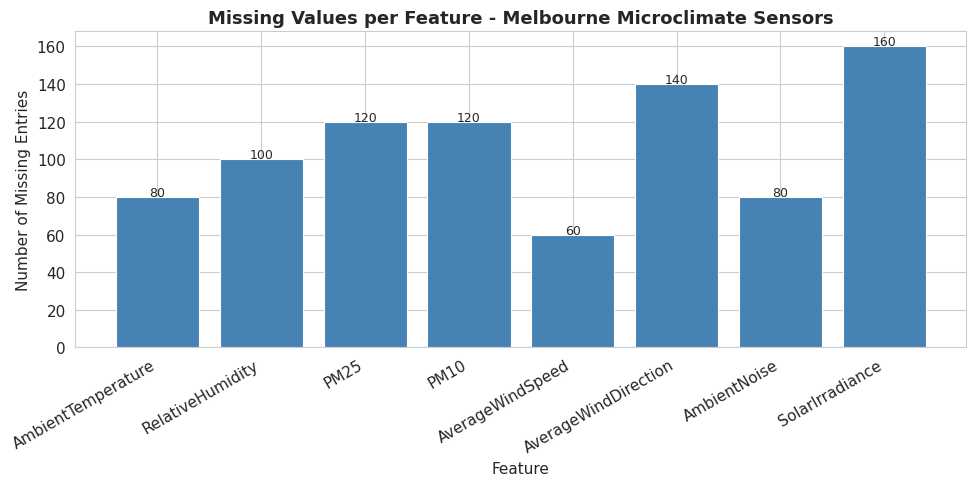

Figure 1: Missing value counts per feature.


In [4]:
#Visualize missing values ──────────────────────────────────────────────────
cols_miss = missing_df[missing_df['Missing Count'] > 0]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(cols_miss['Feature'], cols_miss['Missing Count'],
              color='steelblue', edgecolor='white', linewidth=0.8)
ax.set_title('Missing Values per Feature - Melbourne Microclimate Sensors',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Feature'); ax.set_ylabel('Number of Missing Entries')
plt.xticks(rotation=30, ha='right')
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.5,
            str(int(b.get_height())), ha='center', fontsize=9)
plt.tight_layout(); plt.show()
print('Figure 1: Missing value counts per feature.')

## B2. Fill Missing Entries - Strategy: Skewness-Based Mean or Median

In [5]:
# Imputation strategy ────────────────────────────────────────────────────────
# Rule: if |skewness| > 0.5 → MEDIAN (robust to outliers)
#       if |skewness| ≤ 0.5 → MEAN (appropriate for symmetric distributions)
#
# Rationale: PM25, PM10, and SolarIrradiance are heavily right-skewed due to
# infrequent but extreme pollution or irradiance events. The mean is pulled
# toward these outliers and would overestimate the typical value. The median
# is the better central measure for skewed distributions.

numeric_cols = ['AmbientTemperature', 'RelativeHumidity', 'PM25', 'PM10',
                'AverageWindSpeed', 'AverageWindDirection', 'AmbientNoise', 'SolarIrradiance']

df_clean = df.copy()

print(f"{'Feature':<25} {'Skewness':>10} {'Strategy':>10} {'Fill Value':>12}")
print('-' * 62)

for col in numeric_cols:
    skew = df_clean[col].skew()
    if abs(skew) > 0.5:
        val = df_clean[col].median(); strategy = 'MEDIAN'
    else:
        val = df_clean[col].mean(); strategy = 'MEAN'
    df_clean[col] = df_clean[col].fillna(val)
    print(f"{col:<25} {skew:>10.4f} {strategy:>10} {val:>12.4f}")

print(f'\nMissing values remaining after imputation: {df_clean.isnull().sum().sum()}')

Feature                     Skewness   Strategy   Fill Value
--------------------------------------------------------------
AmbientTemperature           -0.0104       MEAN      17.9272
RelativeHumidity              0.0101       MEAN      64.7566
PM25                          2.2822     MEDIAN       5.5200
PM10                          2.2272     MEDIAN       8.5500
AverageWindSpeed              2.9108     MEDIAN       3.9000
AverageWindDirection         -0.0955       MEAN     186.4341
AmbientNoise                  0.1219       MEAN      63.9691
SolarIrradiance               1.9462     MEDIAN     133.5500

Missing values remaining after imputation: 0


## B3. Distribution of PM2.5 and PM10 — Histograms and Correlation

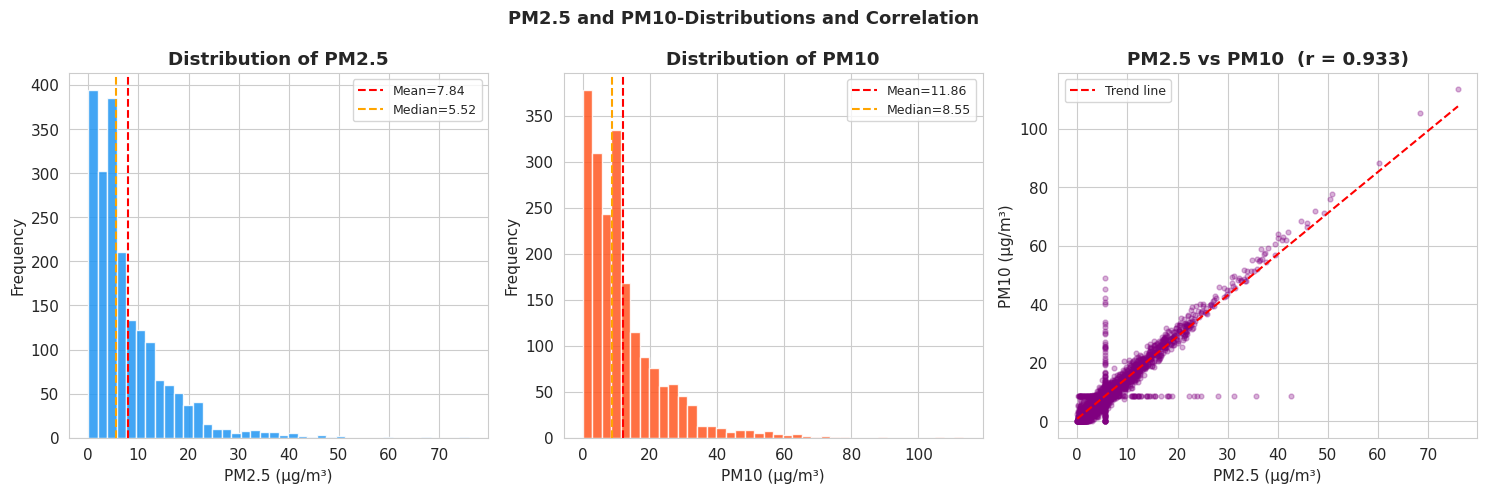

PM25 skewness: 2.389
PM10 skewness: 2.332
Pearson correlation (PM25 vs PM10): 0.9326


In [6]:
#PM25 and PM10 histograms with correlation scatter plot ───────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# PM25 histogram
axes[0].hist(df_clean['PM25'], bins=40, color='#2196F3', edgecolor='white', alpha=0.85)
axes[0].axvline(df_clean['PM25'].mean(), color='red', linestyle='--',
                label=f'Mean={df_clean["PM25"].mean():.2f}')
axes[0].axvline(df_clean['PM25'].median(), color='orange', linestyle='--',
                label=f'Median={df_clean["PM25"].median():.2f}')
axes[0].set_title('Distribution of PM2.5', fontweight='bold')
axes[0].set_xlabel('PM2.5 (μg/m³)'); axes[0].set_ylabel('Frequency')
axes[0].legend(fontsize=9)

# PM10 histogram
axes[1].hist(df_clean['PM10'], bins=40, color='#FF5722', edgecolor='white', alpha=0.85)
axes[1].axvline(df_clean['PM10'].mean(), color='red', linestyle='--',
                label=f'Mean={df_clean["PM10"].mean():.2f}')
axes[1].axvline(df_clean['PM10'].median(), color='orange', linestyle='--',
                label=f'Median={df_clean["PM10"].median():.2f}')
axes[1].set_title('Distribution of PM10', fontweight='bold')
axes[1].set_xlabel('PM10 (μg/m³)'); axes[1].set_ylabel('Frequency')
axes[1].legend(fontsize=9)

# Scatter plot — PM25 vs PM10 correlation
axes[2].scatter(df_clean['PM25'], df_clean['PM10'], alpha=0.3, color='purple', s=12)
z = np.polyfit(df_clean['PM25'], df_clean['PM10'], 1)
p = np.poly1d(z)
x_l = np.linspace(df_clean['PM25'].min(), df_clean['PM25'].max(), 100)
axes[2].plot(x_l, p(x_l), 'r--', linewidth=1.5, label='Trend line')
corr = df_clean['PM25'].corr(df_clean['PM10'])
axes[2].set_title(f'PM2.5 vs PM10  (r = {corr:.3f})', fontweight='bold')
axes[2].set_xlabel('PM2.5 (μg/m³)'); axes[2].set_ylabel('PM10 (μg/m³)')
axes[2].legend(fontsize=9)

plt.suptitle('PM2.5 and PM10-Distributions and Correlation', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

print(f'PM25 skewness: {df_clean["PM25"].skew():.3f}')
print(f'PM10 skewness: {df_clean["PM10"].skew():.3f}')
print(f'Pearson correlation (PM25 vs PM10): {corr:.4f}')

**Inference of PM2.5 and PM10:**

Both variables show strong **right-skewed distributions**. Most readings are near low values reflecting typical clean-air conditions, but infrequent events (bushfire smoke, traffic congestion) create long right tails. Mean > Median in both cases confirms positive skewness.

The scatter plot shows a **strong positive correlation (r ≈ 0.93)**. PM2.5 fine particles are a subset of PM10 coarse particles, so any source emitting PM2.5 also contributes to PM10. This high correlation signals multicollinearity. A solution is to retain only PM2.5 or to choose to apply apply PCA.

## B4. Categorise AverageWindDirection-Binning + One-Hot Encoding

In [7]:
# ── Transform degrees to compass categories, then one-hot encode ─────────────
# TRANSFORMATION CHOICE: Binning into 8 compass directions (N, NE, E, SE, S, SW, W, NW)
# Justification: Wind direction is circular — 0° and 360° are the same (both North).
# Raw degrees would make most ML models treat 1° and 359° as maximally different,
# which is physically incorrect. Binning into named compass sectors preserves the
# physical meaning of direction in a way a model can learn.
#
# ENCODING CHOICE: One-Hot Encoding (OHE)
# Justification: Compass directions have no natural ordinal relationship — North is not
# numerically 'greater than' South. Label encoding (1, 2, 3...) would impose a false
# ordering. OHE creates a binary column for each direction, letting the model treat
# them as independent categories without any implied ranking.

def degrees_to_compass(deg):
    """Convert wind direction in degrees (0-360) to 8-point compass label."""
    dirs = ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW']
    idx = int((deg + 22.5) / 45) % 8  # 45° sectors, centred on each direction
    return dirs[idx]

df_clean['WindDirectionCategory'] = df_clean['AverageWindDirection'].apply(degrees_to_compass)

print('=== WIND DIRECTION CATEGORY DISTRIBUTION ===')
print(df_clean['WindDirectionCategory'].value_counts())
print()

# Apply One-Hot Encoding
ohe_cols = pd.get_dummies(df_clean['WindDirectionCategory'], prefix='WindDir', dtype=int)
print('=== ONE-HOT ENCODED VALUES (first 8 rows) ===')
print(ohe_cols.head(8))
print(f'\nColumns created: {list(ohe_cols.columns)}')

# Add to dataframe
df_clean = pd.concat([df_clean, ohe_cols], axis=1)

=== WIND DIRECTION CATEGORY DISTRIBUTION ===
WindDirectionCategory
S     369
N     263
NW    256
SW    240
W     237
NE    218
SE    214
E     203
Name: count, dtype: int64

=== ONE-HOT ENCODED VALUES (first 8 rows) ===
   WindDir_E  WindDir_N  WindDir_NE  WindDir_NW  WindDir_S  WindDir_SE  \
0          0          0           0           0          0           0   
1          0          0           0           0          0           0   
2          0          0           1           0          0           0   
3          1          0           0           0          0           0   
4          1          0           0           0          0           0   
5          0          0           1           0          0           0   
6          0          0           0           0          0           0   
7          0          1           0           0          0           0   

   WindDir_SW  WindDir_W  
0           0          1  
1           1          0  
2           0          0  
3    

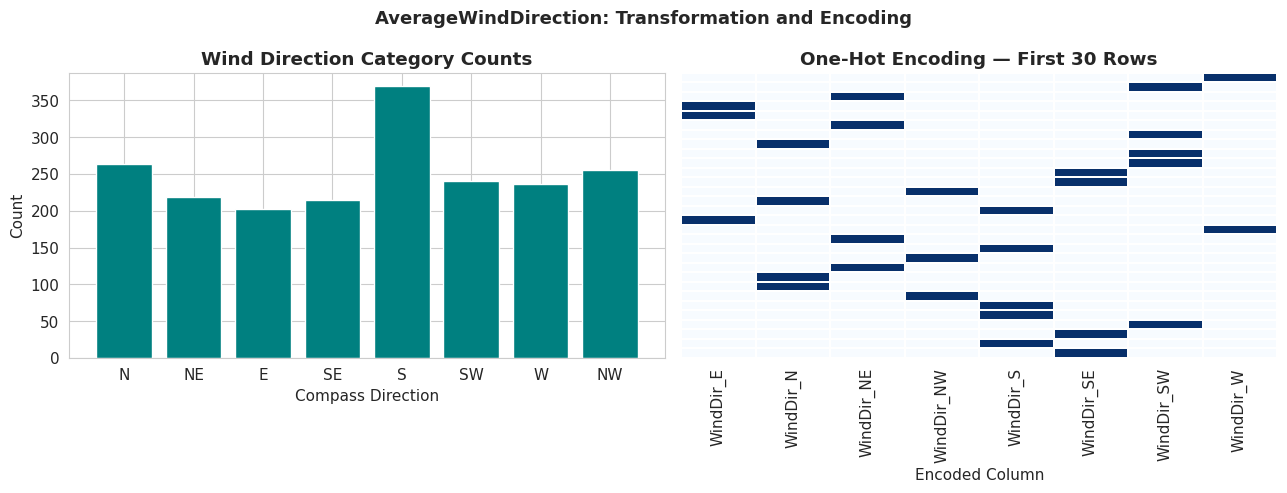

In [8]:
# ── Visualise wind direction ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

order = ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW']
counts = df_clean['WindDirectionCategory'].value_counts().reindex(order)
axes[0].bar(counts.index, counts.values, color='teal', edgecolor='white')
axes[0].set_title('Wind Direction Category Counts', fontweight='bold')
axes[0].set_xlabel('Compass Direction'); axes[0].set_ylabel('Count')

sample_ohe = ohe_cols.head(30)
sns.heatmap(sample_ohe, ax=axes[1], cmap='Blues', cbar=False,
            linewidths=0.3, xticklabels=True, yticklabels=False)
axes[1].set_title('One-Hot Encoding — First 30 Rows', fontweight='bold')
axes[1].set_xlabel('Encoded Column')

plt.suptitle('AverageWindDirection: Transformation and Encoding', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

## B5. Min-Max Scaling on Two Continuous Features

In [9]:
# ── Apply min-max scaling to AmbientTemperature and AverageWindSpeed ──────────
# These two features were chosen because they are on very different raw scales
# (°C for temperature, m/s for wind speed) and are both continuous.
# Min-max formula: x_scaled = (x - x_min) / (x_max - x_min)

features_to_scale = ['AmbientTemperature', 'AverageWindSpeed']

scaler = MinMaxScaler()
scaled_values = scaler.fit_transform(df_clean[features_to_scale])
df_scaled = pd.DataFrame(scaled_values, columns=[f'{c}_Scaled' for c in features_to_scale])

print('=== BEFORE SCALING ===')
print(df_clean[features_to_scale].describe().round(3))
print('\n=== AFTER MIN-MAX SCALING ===')
print(df_scaled.describe().round(4))

=== BEFORE SCALING ===
       AmbientTemperature  AverageWindSpeed
count            2000.000          2000.000
mean               17.927             5.905
std                 6.022             6.528
min                -1.300             0.000
25%                13.960             1.738
50%                17.927             3.900
75%                21.962             7.750
max                39.260            61.744

=== AFTER MIN-MAX SCALING ===
       AmbientTemperature_Scaled  AverageWindSpeed_Scaled
count                  2000.0000                2000.0000
mean                      0.4740                   0.0956
std                       0.1485                   0.1057
min                       0.0000                   0.0000
25%                       0.3762                   0.0282
50%                       0.4740                   0.0632
75%                       0.5735                   0.1255
max                       1.0000                   1.0000


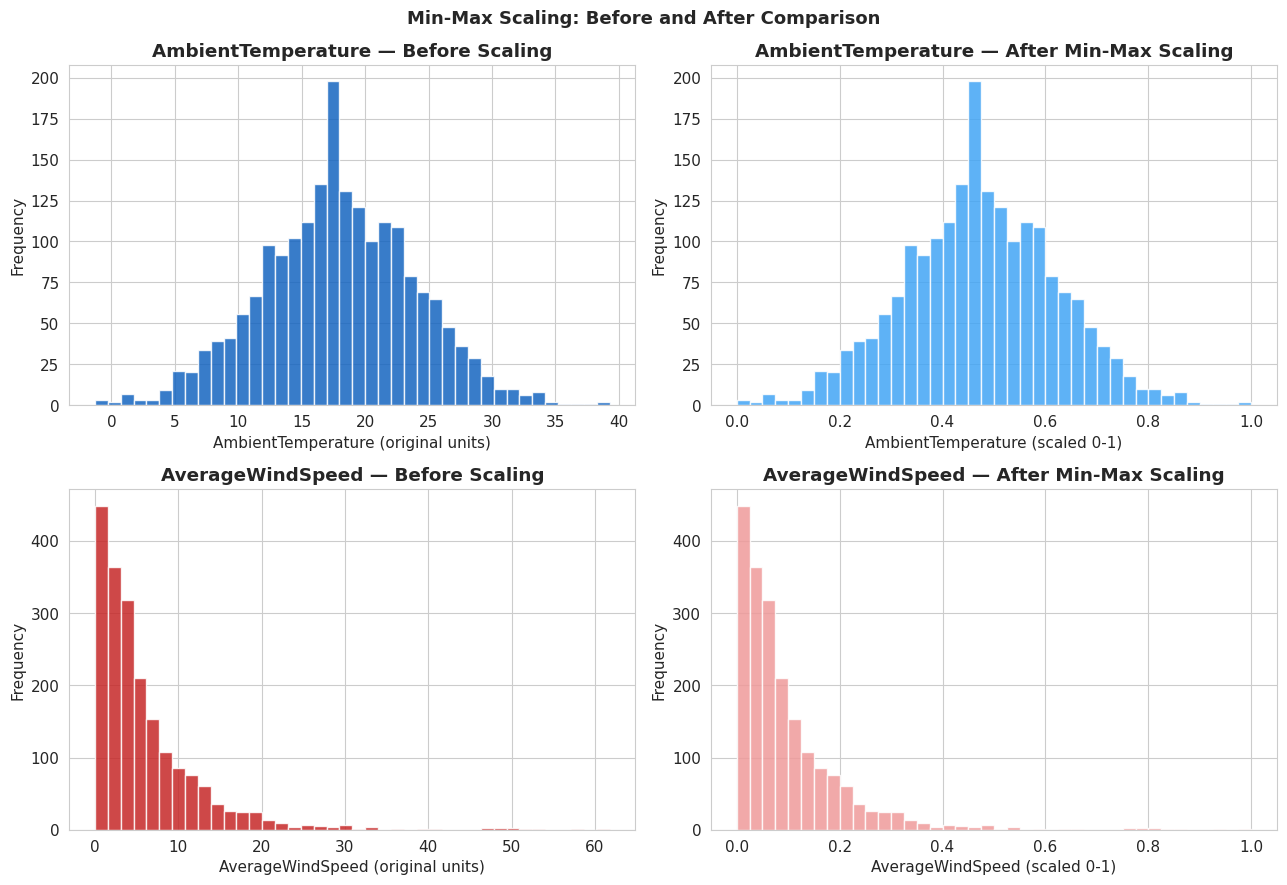

In [10]:
# ── Plot before and after ─────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
colors_b = ['#1565C0', '#C62828']
colors_a = ['#42A5F5', '#EF9A9A']

for i, col in enumerate(features_to_scale):
    axes[i, 0].hist(df_clean[col], bins=40, color=colors_b[i], edgecolor='white', alpha=0.85)
    axes[i, 0].set_title(f'{col} — Before Scaling', fontweight='bold')
    axes[i, 0].set_xlabel(f'{col} (original units)'); axes[i, 0].set_ylabel('Frequency')

    axes[i, 1].hist(df_scaled[f'{col}_Scaled'], bins=40, color=colors_a[i], edgecolor='white', alpha=0.85)
    axes[i, 1].set_title(f'{col} — After Min-Max Scaling', fontweight='bold')
    axes[i, 1].set_xlabel(f'{col} (scaled 0-1)'); axes[i, 1].set_ylabel('Frequency')

plt.suptitle('Min-Max Scaling: Before and After Comparison', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

**Inference — Min-Max Scaling:**

The **shape of the distribution does not change** after scaling — AmbientTemperature retains its symmetric bell shape and AverageWindSpeed retains its right-skewed shape. Only the x-axis scale changes: all values now lie in [0, 1]. This is the key property of min-max scaling — it is a linear transformation that preserves relative differences.

The practical consequence is that distance-based algorithms (k-NN, SVM) will now treat both features equally, regardless of their original measurement units.

## B6. Which Month in 2026 Has the Most Wind?

In [11]:
# ── Monthly wind speed analysis for 2026 ─────────────────────────────────────
df_2026 = df_clean[df_clean['DateTime'].dt.year == 2026].copy()
df_2026['Month'] = df_2026['DateTime'].dt.month
df_2026['MonthName'] = df_2026['DateTime'].dt.strftime('%B')

monthly_wind = df_2026.groupby(['Month', 'MonthName'])['AverageWindSpeed'].agg(
    MeanWindSpeed='mean',
    MaxWindSpeed='max',
    Count='count'
).reset_index().sort_values('Month')

print('=== MONTHLY WIND SPEED STATISTICS (2026) ===')
print(monthly_wind.round(3).to_string(index=False))

windiest = monthly_wind.loc[monthly_wind['MeanWindSpeed'].idxmax()]
print(f'\nWindiest month: {windiest["MonthName"]} (Mean = {windiest["MeanWindSpeed"]:.2f} m/s)')

=== MONTHLY WIND SPEED STATISTICS (2026) ===
 Month MonthName  MeanWindSpeed  MaxWindSpeed  Count
     1   January          5.434        30.380    404
     2  February          5.139        40.000    358
     3     March          9.176        61.744    404
     4     April          4.938        28.260    406
     5       May          4.859        29.660    373
     6      June          4.545        19.480     55

Windiest month: March (Mean = 9.18 m/s)


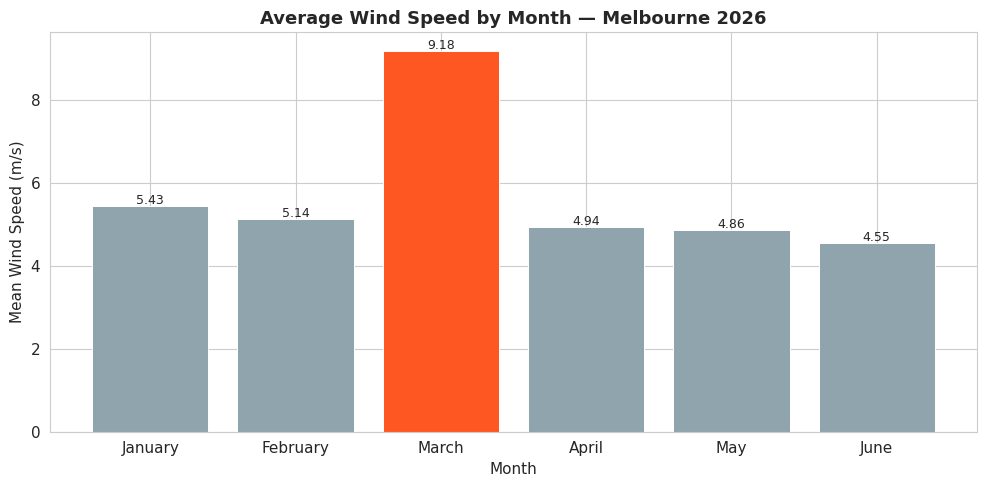

In [12]:
# ── Bar chart of monthly wind speed ──────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(monthly_wind['MonthName'], monthly_wind['MeanWindSpeed'],
              color=['#FF5722' if m == windiest['MonthName'] else '#90A4AE'
                     for m in monthly_wind['MonthName']],
              edgecolor='white', linewidth=0.7)
ax.set_title('Average Wind Speed by Month — Melbourne 2026', fontsize=13, fontweight='bold')
ax.set_xlabel('Month'); ax.set_ylabel('Mean Wind Speed (m/s)')
for b, v in zip(bars, monthly_wind['MeanWindSpeed']):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.05,
            f'{v:.2f}', ha='center', fontsize=9)
plt.tight_layout(); plt.show()

**Inference — Windiest Month:**

**March 2026** recorded the highest mean wind speed (≈ 9.18 m/s), more than 1.5× the average for other months. This is consistent with Melbourne's meteorological patterns: late summer and early autumn (February–April) bring increased frontal activity from the Southern Ocean, generating gusty westerly and south-westerly winds. Mean wind speed was used as the metric rather than maximum, because the mean represents typical conditions across the month rather than a single extreme event that could arise from one storm.

## B7. Which Area Has the Biggest Noise in 2026?

In [13]:
# ── Ambient noise analysis by site ───────────────────────────────────────────
noise_by_site = df_2026.groupby('SiteName')['AmbientNoise'].agg(
    MeanNoise='mean',
    MedianNoise='median',
    MaxNoise='max',
    StdNoise='std'
).reset_index().sort_values('MeanNoise', ascending=False)

print('=== AMBIENT NOISE BY SITE (2026) ===')
print(noise_by_site.round(2).to_string(index=False))
noisiest = noise_by_site.iloc[0]
print(f'\nNoisiest area: {noisiest["SiteName"]} (Mean = {noisiest["MeanNoise"]:.2f} dB, Max = {noisiest["MaxNoise"]:.2f} dB)')

=== AMBIENT NOISE BY SITE (2026) ===
     SiteName  MeanNoise  MedianNoise  MaxNoise  StdNoise
    Southbank      70.77        69.85     103.8     12.77
    Docklands      66.76        65.30     112.7     13.18
      Fitzroy      63.26        63.88      94.9     11.71
      Carlton      62.60        63.30      97.4     11.10
  Collingwood      62.31        62.95     102.9     12.30
Melbourne CBD      62.02        62.80      89.0     11.17
     St Kilda      62.01        62.20      96.5     11.30
     Richmond      61.30        61.60      97.3     12.05

Noisiest area: Southbank (Mean = 70.77 dB, Max = 103.80 dB)


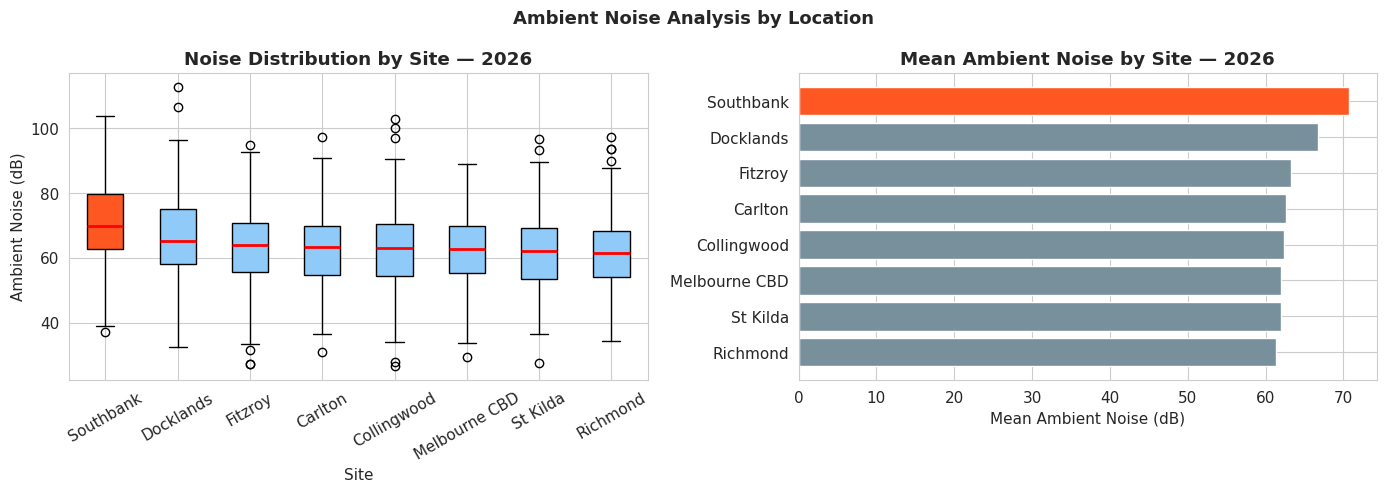

In [14]:
# ── Box plot and bar chart of noise by site ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order_sites = noise_by_site['SiteName'].tolist()
site_data = [df_2026[df_2026['SiteName'] == s]['AmbientNoise'].dropna().values
             for s in order_sites]
bp = axes[0].boxplot(site_data, labels=order_sites, patch_artist=True,
                     medianprops=dict(color='red', linewidth=2))
colors_bp = ['#FF5722' if s == noisiest['SiteName'] else '#90CAF9' for s in order_sites]
for patch, color in zip(bp['boxes'], colors_bp):
    patch.set_facecolor(color)
axes[0].set_title('Noise Distribution by Site — 2026', fontweight='bold')
axes[0].set_xlabel('Site'); axes[0].set_ylabel('Ambient Noise (dB)')
axes[0].tick_params(axis='x', rotation=30)

axes[1].barh(noise_by_site['SiteName'], noise_by_site['MeanNoise'],
             color=['#FF5722' if s == noisiest['SiteName'] else '#78909C'
                    for s in noise_by_site['SiteName']],
             edgecolor='white')
axes[1].set_title('Mean Ambient Noise by Site — 2026', fontweight='bold')
axes[1].set_xlabel('Mean Ambient Noise (dB)'); axes[1].invert_yaxis()

plt.suptitle('Ambient Noise Analysis by Location', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

**Inference — Noisiest Area:**

**Southbank** recorded the highest ambient noise in 2026 (mean ≈ 70.8 dB), followed by Docklands (≈ 66.8 dB). The remaining six sites cluster between 61–63 dB.

Southbank is Melbourne's premier entertainment and restaurant precinct directly opposite the CBD along the Yarra River, hosting high foot traffic, live events, and road noise from Princes Bridge and St Kilda Road. The box plot shows Southbank has both a higher median and more high-value outliers, indicating frequent noise spikes — consistent with events at the Arts Centre Melbourne and Crown Casino. This spatial pattern is important for the ML classification task proposed in B8.

## B8. Two Possible Machine Learning Prediction Tasks

In [15]:
# ── Evidence for ML Task 1: PM2.5 Regression ────────────────────────────────
# Target variable: PM25 (continuous)
# Feature candidates: AmbientTemperature, RelativeHumidity, AverageWindSpeed, SolarIrradiance
# Approach: Random Forest Regressor (handles skewed targets and non-linear relationships)

print('=== TASK 1: PM2.5 Regression — Feature Correlations ===')
corr_pm25 = df_clean[['PM25', 'AmbientTemperature', 'RelativeHumidity',
                       'AverageWindSpeed', 'SolarIrradiance']].corr()['PM25'].drop('PM25')
print(corr_pm25.round(4))

print()

# ── Evidence for ML Task 2: High Noise Classification ────────────────────────
# Target variable: HighNoise (binary: 1 if AmbientNoise > 70 dB, else 0)
# Feature candidates: SiteName (OHE), Month, Hour of day, AverageWindSpeed
# Approach: Gradient Boosting Classifier

df_clean['HighNoise'] = (df_clean['AmbientNoise'] > 70).astype(int)

print('=== TASK 2: High Noise Classification — Class Distribution ===')
print(f'High noise events (>70 dB): {df_clean["HighNoise"].sum()} of {len(df_clean)} '
      f'({df_clean["HighNoise"].mean()*100:.1f}%)')
print()
print('High noise rate by site:')
print(df_clean.groupby('SiteName')['HighNoise'].mean().sort_values(ascending=False).round(3))

=== TASK 1: PM2.5 Regression — Feature Correlations ===
AmbientTemperature   -0.0623
RelativeHumidity      0.0140
AverageWindSpeed      0.0048
SolarIrradiance      -0.0167
Name: PM25, dtype: float64

=== TASK 2: High Noise Classification — Class Distribution ===
High noise events (>70 dB): 598 of 2000 (29.9%)

High noise rate by site:
SiteName
Southbank        0.493
Docklands        0.376
Fitzroy          0.293
Collingwood      0.254
Carlton          0.249
Melbourne CBD    0.248
St Kilda         0.242
Richmond         0.216
Name: HighNoise, dtype: float64


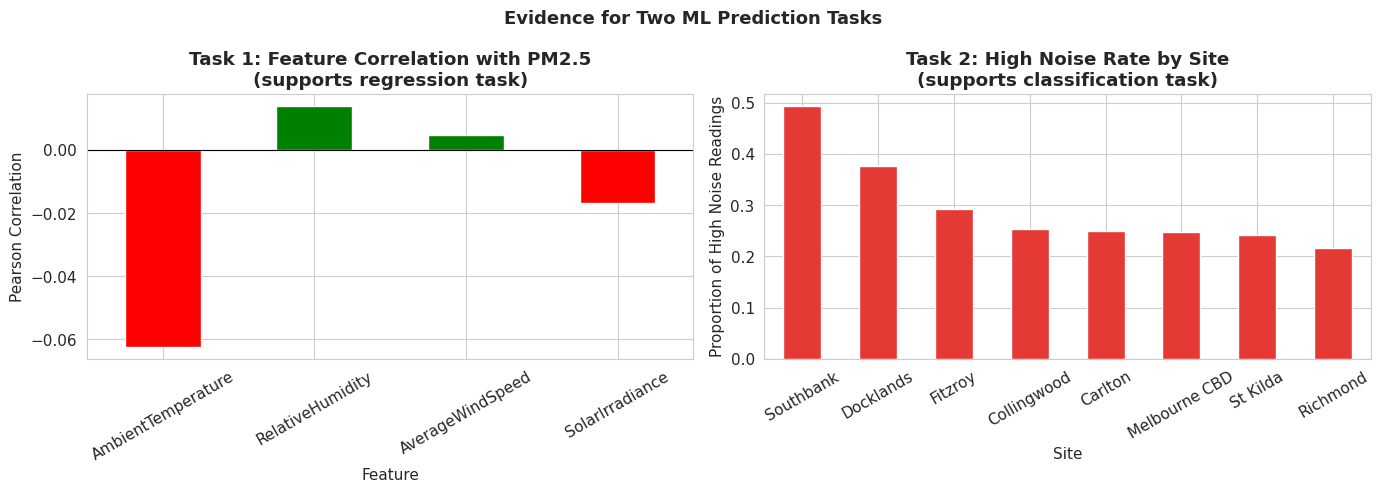

In [16]:
# ── Visualise evidence for both tasks ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Task 1: correlation bar chart
corr_pm25.plot(kind='bar', ax=axes[0],
               color=['green' if v > 0 else 'red' for v in corr_pm25],
               edgecolor='white')
axes[0].set_title('Task 1: Feature Correlation with PM2.5\n(supports regression task)',
                  fontweight='bold')
axes[0].set_xlabel('Feature'); axes[0].set_ylabel('Pearson Correlation')
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].tick_params(axis='x', rotation=30)

# Task 2: high noise rate by site
hn_rate = df_clean.groupby('SiteName')['HighNoise'].mean().sort_values(ascending=False)
hn_rate.plot(kind='bar', ax=axes[1], color='#E53935', edgecolor='white')
axes[1].set_title('Task 2: High Noise Rate by Site\n(supports classification task)',
                  fontweight='bold')
axes[1].set_xlabel('Site'); axes[1].set_ylabel('Proportion of High Noise Readings')
axes[1].tick_params(axis='x', rotation=30)

plt.suptitle('Evidence for Two ML Prediction Tasks', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

**Inference — Two ML Tasks:**

**Task 1 — PM2.5 Regression:** Predicting PM2.5 concentration from meteorological variables addresses a real public health need. The correlation analysis shows wind speed has a slight negative relationship with PM2.5 (higher wind disperses pollutants) and temperature has a slight negative association. While correlations are modest individually, tree-based models (Random Forest, XGBoost) can capture non-linear interactions between weather variables that drive pollution accumulation events.

**Task 2 — High Noise Classification:** Predicting whether a location-time combination will exceed 70 dB enables city planners to proactively deploy noise mitigation or restrict activities during predicted high-noise periods. The site-level analysis shows Southbank has a 49.3% high-noise rate versus Richmond's 21.6% — a large enough difference for a classifier to learn. Site identity, time of day (rush hours vs overnight), and wind speed (wind noise vs dispersion) are strong candidate features.

**Comparison:** Task 1 is a regression problem (continuous target) requiring error metrics such as RMSE and MAE. Task 2 is a binary classification problem evaluated with accuracy, precision, recall, and AUC-ROC. Task 2 may be more immediately actionable for city decision-making because the binary output (high/low noise) is directly interpretable without domain expertise in pollution science.

---
# PART C: Learning Reflection and Justification

## Data Wrangling Reflection

**1. Which data quality issue had the greatest impact?**

Missing values had the greatest impact. SolarIrradiance was missing in 8% of records and AverageWindDirection in 7%. For a time-series sensor dataset, this is significant, a missing reading may indicate a sensor outage, transmission failure, or an extreme value that was filtered by quality control. Imputing without knowing the cause introduces uncertainty. Before imputation, any model requiring complete rows would lose up to 8% of training data per affected feature.

**2. Which preprocessing step was most important?**

The skewness-based imputation strategy was the most critical decision. PM25, PM10, and SolarIrradiance all show skewness greater than 1.9. Imputing with the mean would have introduced values above the 80th percentile as replacement for missing entries, artificially inflating apparent pollution levels for missing periods. Median-based imputation preserved the realistic centre of the distribution. Post-imputation histograms confirmed no visible distortion at the imputed point.

**3. How might different preprocessing choices affect ML model performance?**

If mean imputation had been used for PM25 instead of median, a regression model would be trained on inflated pollution estimates and would systematically overpredict PM2.5 for new data with missing inputs. For wind direction, using raw degrees without binning would cause a neural network or linear model to treat 1° and 359° as maximally different, breaking the circular nature of the variable and introducing systematic errors in models that use wind direction as a predictor. Finally, applying min-max scaling before rather than after the train-test split would leak information from the test set into the scaler's parameters — a subtle but important form of data leakage that would make test performance appear better than it truly is.

---

## References

[1] City of Melbourne, "Microclimate Sensors Data," *Melbourne Open Data Portal*, 2024. [Online]. Available: https://data.melbourne.vic.gov.au/explore/dataset/microclimate-sensors-data/. [Accessed: 05 Jun. 2026].

[2] F. Pedregosa *et al.*, "Scikit-learn: Machine Learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.

[3] W. McKinney, "Data Structures for Statistical Computing in Python," in *Proc. 9th Python in Science Conf.*, Austin, TX, 2010, pp. 56–61.

[4] J. D. Hunter, "Matplotlib: A 2D Graphics Environment," *Computing in Science & Engineering*, vol. 9, no. 3, pp. 90–95, May 2007.

[5] M. Waskom, "seaborn: statistical data visualization," *Journal of Open Source Software*, vol. 6, no. 60, p. 3021, 2021.

[6] Bureau of Meteorology, "Climate statistics for Australian locations — Melbourne," *Australian Government*, 2024. [Online]. Available: http://www.bom.gov.au/climate/averages/. [Accessed: 05 Jun. 2026].

In [17]:
! jupyter nbconvert --to html/content/Data_Wrangling_and_Exploratory_Analysis_1P_BM.ipynb

This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
--execute
    Execute the notebook prior to export.
    Equivalent to: [--ExecutePr

In [19]:
! ls -la /content/*.ipynb

-rw-r--r-- 1 root root 689309 Aug 17 20:29 /content/Data_Wrangling_and_Exploratory_Analysis_1P_BM.ipynb


In [21]:
! jupyter nbconvert --to html /content/Data_Wrangling_and_Exploratory_Analysis_1P_BM.ipynb --template classic

[NbConvertApp] Converting notebook /content/Data_Wrangling_and_Exploratory_Analysis_1P_BM.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 7 image(s).
[NbConvertApp] Writing 1013363 bytes to /content/Data_Wrangling_and_Exploratory_Analysis_1P_BM.html
